# Inspect the anu-tub run

A quick look at the inputs and first model output. Figures are displayed here only. This one-day run checks the setup; the circulation has not reached equilibrium.

In [8]:
%matplotlib inline
from pathlib import Path
import xarray as xr
import matplotlib.pyplot as plt

## Open the files

Change `output000` below to inspect a later run. Paths work from this notebook or the configuration directory.

In [9]:
root = Path.cwd()
if root.name == 'analysis':
    root = root.parent

output = root / 'archive' / 'output002'
time_decoder = xr.coders.CFDatetimeCoder(use_cftime=True)

topog = xr.open_dataset(root / 'input' / 'topog.nc')
forcing = xr.open_dataset(root / 'input' / 'forcing.nc')
sst = xr.open_dataset(root / 'input' / 'sst.nc')
static = xr.open_dataset(output / 'ocean_static.nc', decode_times=time_decoder)
daily = xr.open_dataset(output / 'ocean_daily.nc', decode_times=time_decoder)
vertical = xr.open_dataset(output / 'ocean_month_z.nc', decode_times=time_decoder)
stats = xr.open_dataset(output / 'ocean.stats.nc', decode_times=time_decoder)

print('Daily output times:', daily.time.values)
daily

Daily output times: [cftime.DatetimeNoLeap(1, 1, 3, 12, 0, 0, 0, has_year_zero=True)
 cftime.DatetimeNoLeap(1, 1, 4, 12, 0, 0, 0, has_year_zero=True)
 cftime.DatetimeNoLeap(1, 1, 5, 12, 0, 0, 0, has_year_zero=True)
 cftime.DatetimeNoLeap(1, 1, 6, 12, 0, 0, 0, has_year_zero=True)
 cftime.DatetimeNoLeap(1, 1, 7, 12, 0, 0, 0, has_year_zero=True)
 cftime.DatetimeNoLeap(1, 1, 8, 12, 0, 0, 0, has_year_zero=True)
 cftime.DatetimeNoLeap(1, 1, 9, 12, 0, 0, 0, has_year_zero=True)
 cftime.DatetimeNoLeap(1, 1, 10, 12, 0, 0, 0, has_year_zero=True)
 cftime.DatetimeNoLeap(1, 1, 11, 12, 0, 0, 0, has_year_zero=True)
 cftime.DatetimeNoLeap(1, 1, 12, 12, 0, 0, 0, has_year_zero=True)
 cftime.DatetimeNoLeap(1, 1, 13, 12, 0, 0, 0, has_year_zero=True)
 cftime.DatetimeNoLeap(1, 1, 14, 12, 0, 0, 0, has_year_zero=True)
 cftime.DatetimeNoLeap(1, 1, 15, 12, 0, 0, 0, has_year_zero=True)
 cftime.DatetimeNoLeap(1, 1, 16, 12, 0, 0, 0, has_year_zero=True)
 cftime.DatetimeNoLeap(1, 1, 17, 12, 0, 0, 0, has_year_zero=Tru

<xarray.Dataset> Size: 64MB
Dimensions:     (time: 31, yh: 800, xh: 160, xq: 161, yq: 801, nv: 2)
Coordinates:
  * time        (time) object 248B 0001-01-03 12:00:00 ... 0001-02-02 12:00:00
  * yh          (yh) float64 6kB -70.15 -70.07 -69.98 ... 69.98 70.07 70.15
  * xh          (xh) float64 1kB 0.125 0.375 0.625 0.875 ... 39.38 39.63 39.88
  * xq          (xq) float64 1kB 0.0 0.25 0.5 0.75 1.0 ... 39.25 39.5 39.75 40.0
  * yq          (yq) float64 6kB -70.19 -70.11 -70.02 ... 70.02 70.11 70.19
  * nv          (nv) float64 16B 1.0 2.0
Data variables:
    zos         (time, yh, xh) float32 16MB ...
    tos         (time, yh, xh) float32 16MB ...
    umo_2d      (time, yh, xq) float32 16MB ...
    vmo_2d      (time, yq, xh) float32 16MB ...
    average_T1  (time) object 248B ...
    average_T2  (time) object 248B ...
    average_DT  (time) float64 248B ...
    time_bnds   (time, nv) float64 496B ...
Attributes:
    NumFilesInSet:     1
    title:             ANU_tub Sector
    associated_files:  areacello: ocean_static.nc
    grid_type:         regular
    grid_tile:         N/A

## Bathymetry and forcing

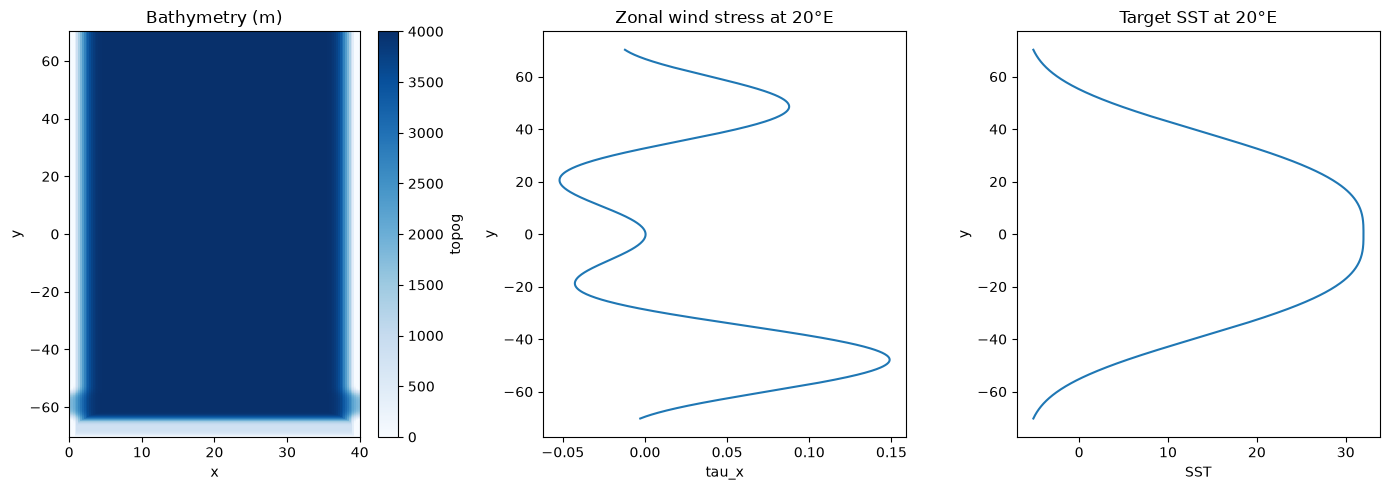

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
topog.topog.plot(ax=axes[0], cmap='Blues')
axes[0].set_title('Bathymetry (m)')
forcing.tau_x.sel(x=20, method='nearest').plot(ax=axes[1], y='y')
axes[1].set_title('Zonal wind stress at 20°E')
sst.SST.sel(x=20, method='nearest').plot(ax=axes[2], y='y')
axes[2].set_title('Target SST at 20°E')
plt.tight_layout()

## Surface temperature and sea-surface height

The last available daily mean, masked over land.

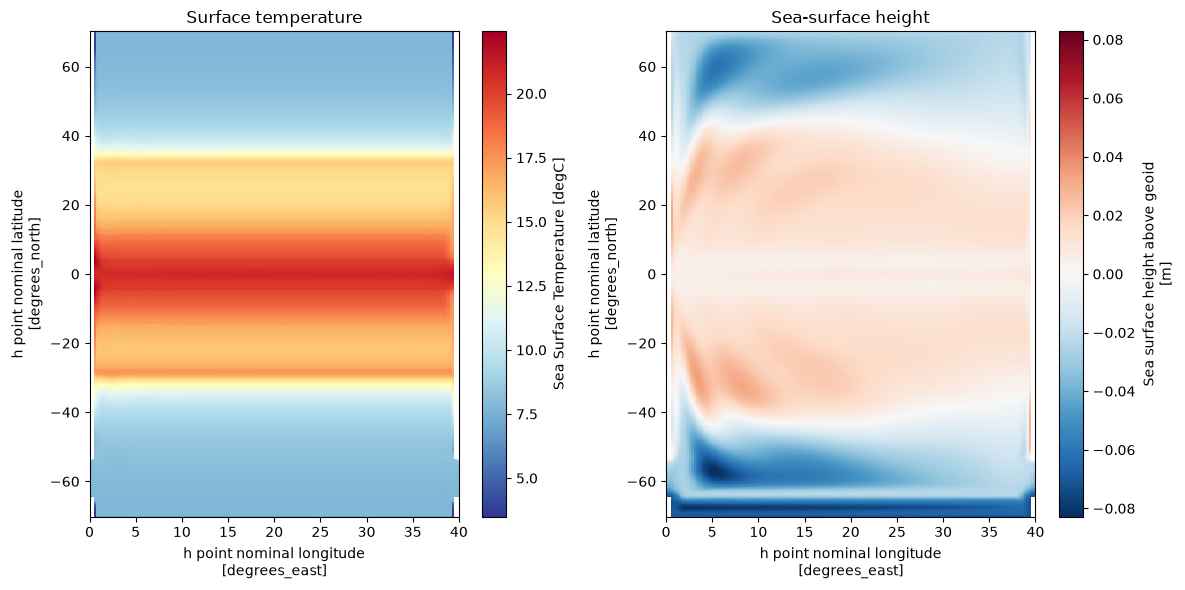

In [11]:
wet = static.wet.squeeze(drop=True) > 0
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
daily.tos.isel(time=-1).where(wet).plot(ax=axes[0], cmap='RdYlBu_r')
axes[0].set_title('Surface temperature')
daily.zos.isel(time=-1).where(wet).plot(ax=axes[1], cmap='RdBu_r')
axes[1].set_title('Sea-surface height')
plt.tight_layout()

## Temperature section at 20°E

This uses the last available record from the monthly diagnostic file. Check its time bounds: a one-day run does not contain a complete monthly mean.

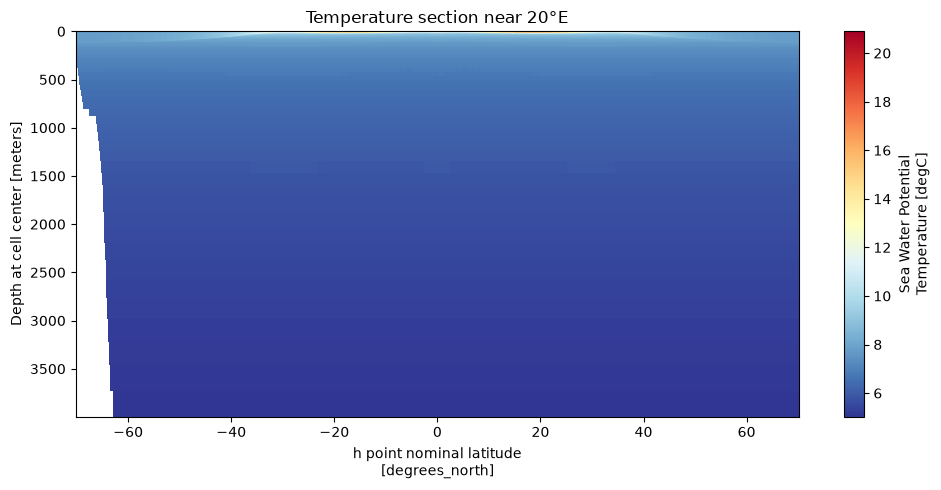

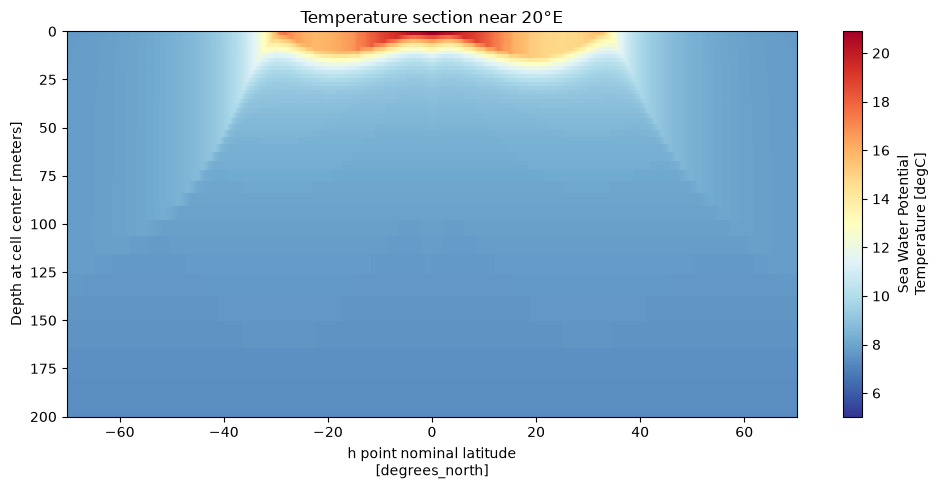

In [18]:
# print('Averaging bounds:', vertical.time_bnds.values)
section = vertical.thetao.isel(time=-1).sel(xh=20, method='nearest')
plt.figure(figsize=(10, 5))
section.plot(x='yh', y='z_l', yincrease=False, cmap='RdYlBu_r')
plt.title('Temperature section near 20°E')
plt.tight_layout()
plt.figure(figsize=(10, 5))
section.plot(x='yh', y='z_l', yincrease=False, cmap='RdYlBu_r', ylim=(200,0))
plt.title('Temperature section near 20°E')
plt.tight_layout()

## Basic model checks

Energy and maximum transport CFL from the model statistics. With only two records these are startup checks, not long-term trends.

tos min: 3.4993703365325928 max: 22.42696762084961 degC
zos min: -0.08280770480632782 max: 0.03443117067217827 m


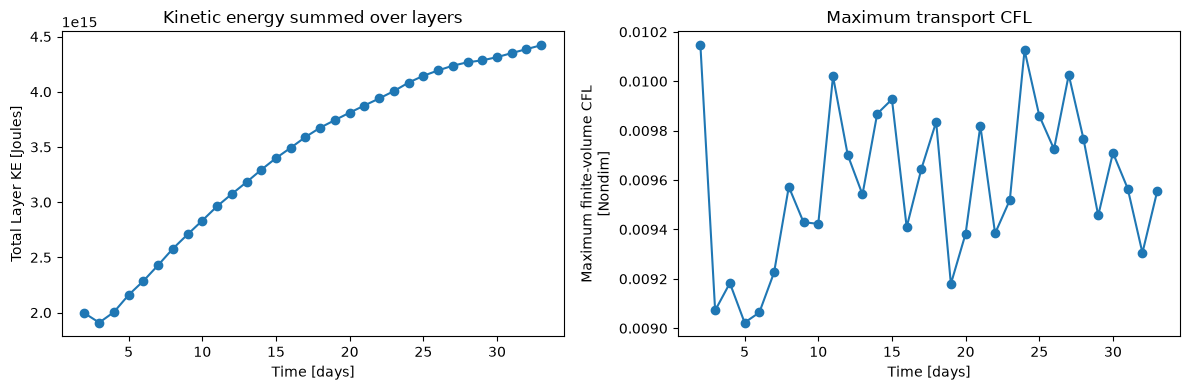

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
stats.KE.sum('Layer').plot(ax=axes[0], marker='o')
axes[0].set_title('Kinetic energy summed over layers')
stats.max_CFL_trans.plot(ax=axes[1], marker='o')
axes[1].set_title('Maximum transport CFL')
plt.tight_layout()

for name in ['tos', 'zos']:
    field = daily[name].isel(time=-1).where(wet)
    print(name, 'min:', float(field.min()), 'max:', float(field.max()), field.attrs.get('units', ''))

In [14]:
for dataset in [topog, forcing, sst, static, daily, vertical, stats]:
    dataset.close()